# Routing for Agent KIO — CET351 Machine Learning, Lecture Project 1
**Team:** Ahmed Mohamed Aldamardash · Moaaz Abd Aljawwad · Omar Ahmed Ramadan

Agent KIO routes every customer message to one of two agents: **0 = support**, **1 = sales**.
This notebook builds that router twice and compares the two:

1. **Traditional ML classifier**: logistic regression with degree-2 polynomial features on two numeric features.
2. **Decision model**: `facebook/bart-large-mnli` (open-source, MIT licence) used as a zero-shot decision model with routing instructions and a validated structured output.

Run with **Runtime → Run all** (about 3 minutes, CPU is enough).

In [1]:
!pip -q install transformers scikit-learn pandas matplotlib > /dev/null
import json, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
REPO = "https://raw.githubusercontent.com/Ahmed-Aldmrdash/ml-project01-agent-kio-routing/main/data/"
SEED = 42

## 1 · Dataset
60 synthetic English messages from customers of an industrial-equipment supplier (30 support, 30 sales). Each intent was written as an original and a paraphrase (`group_id`). The split is **by group**, so a paraphrase never leaks between train and test. `stress_test.csv` holds 8 extra hard messages written after the split.

In [2]:
df = pd.read_csv(REPO + "kio_routing_dataset.csv")
stress = pd.read_csv(REPO + "stress_test.csv")
print(df.groupby(["split", "label_name"]).size().unstack())
print("\ncase types:", df.case_type.value_counts().to_dict())
df.sample(6, random_state=SEED)[["id", "message", "label_name", "case_type", "split"]]

label_name  sales  support
split                     
test           10       10
train          20       20

case types: {'paraphrase': 46, 'negation': 6, 'mixed': 4, 'existing order (sales words)': 2, 'existing customer, new purchase': 2}


,id,message,label_name,case_type,split
0,M01,Our CNC lathe stopped mid-cycle and shows spin...,support,paraphrase,test
5,M06,Not looking for a new unit - our existing air ...,support,negation,train
36,M37,Do you sell collaborative robots for palletizing?,sales,paraphrase,train
45,M46,Our managers want a product demo of the manufa...,sales,paraphrase,train
13,M14,Your service engineer missed the appointment a...,support,paraphrase,test
54,M55,Can your team quote a turnkey packaging line f...,sales,paraphrase,test


## 2 · Traditional ML classifier
**Features (numeric):** `support_score` = number of problem cues (error, leak, late, warranty …) and `sales_score` = number of purchase cues (quote, price, buy, demo …). A cue within 3 words after *no / not / don't / nothing* counts **−1**, so *"no issues"* lowers the support score.

**Model:** StandardScaler → PolynomialFeatures(degree=2) → LogisticRegression(C=1). Flag 1 (sales) when P(sales) ≥ 0.5.

In [3]:
SUPPORT_STEMS = ["error","alarm","fault","fail","broke","broken","stop","down","leak","wrong","late","delay","arriv",
 "missing","miss","repair","fix","technician","engineer","warrant","replace","complain","issue","problem","noise","vibrat",
 "overheat","burn","scorch","crack","lock","login","access","twice","refund","invoice","billed","charged","correct","help",
 "existing","already","since","after","keeps","again","can't","cannot","won't","doesn't","don't fit","not working","differ","match"]
SALES_STEMS = ["quote","pric","cost","buy","purchas","order","lease","leasing","financ","discount","bulk","demo","catalog",
 "brochure","upgrade","package","plan$","plans$","subscription","proposal","propose","offer","sell","available","lead time",
 "deliver","new","add","expand","another","second","third","interested","training","licen","install","turnkey","how much"]
NEG = {"no","not","don't","dont","nothing","never","isn't","without"}

def hits(word, stems):
    for s in stems:
        if " " in s: continue
        if s.endswith("$"):
            if word == s[:-1]: return True
        elif word.startswith(s): return True
    return False

def featurize(text):
    t = text.lower(); sup = sal = 0; neg = 0
    for w in re.findall(r"[a-z0-9']+", t):
        if w in NEG: neg = 3; continue
        s_hit, p_hit = hits(w, SUPPORT_STEMS), hits(w, SALES_STEMS)
        if neg > 0: sup -= s_hit; sal -= p_hit
        else: sup += s_hit; sal += p_hit
        neg = max(0, neg - 1)
    sup += sum(t.count(p) for p in SUPPORT_STEMS if " " in p)
    sal += sum(t.count(p) for p in SALES_STEMS if " " in p)
    return [sup, sal]

X = np.array([featurize(m) for m in df.message], float)
Xs = np.array([featurize(m) for m in stress.message], float)
tr, te = (df.split == "train").values, (df.split == "test").values
df["support_score"], df["sales_score"] = X[:, 0], X[:, 1]
df[["id", "message", "support_score", "sales_score", "label"]].head(6)

,id,message,support_score,sales_score,label
0,M01,Our CNC lathe stopped mid-cycle and shows spin...,3.0,0.0,0
1,M02,The lathe you installed last month keeps throw...,2.0,1.0,0
2,M03,The replacement bearings you shipped are the w...,2.0,0.0,0
3,M04,We received bearings for the hydraulic press b...,0.0,0.0,0
4,M05,"I don't want to buy a new compressor, I need t...",1.0,0.0,0
5,M06,Not looking for a new unit - our existing air ...,3.0,1.0,0


In [4]:
ml = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), LogisticRegression(C=1.0, max_iter=1000))
ml.fit(X[tr], df.label[tr])
svm = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=2, coef0=1, C=1.0)).fit(X[tr], df.label[tr])
df["ml_pred"] = ml.predict(X); stress["ml_pred"] = ml.predict(Xs)
for name, m in [("LogReg deg-2", ml), ("SVM poly deg-2", svm)]:
    print(f"{name:15s} train {accuracy_score(df.label[tr], m.predict(X[tr])):.2f} | test {accuracy_score(df.label[te], m.predict(X[te])):.2f} | stress {accuracy_score(stress.label, m.predict(Xs)):.2f}")
print("coefficients [x1, x2, x1^2, x1x2, x2^2]:", ml[-1].coef_.round(2), "bias", ml[-1].intercept_.round(2))

LogReg deg-2    train 0.95 | test 1.00 | stress 0.62
SVM poly deg-2  train 0.95 | test 0.95 | stress 0.50
coefficients [x1, x2, x1^2, x1x2, x2^2]: [[-1.72  1.41 -0.22 -0.54 -0.4 ]] bias [0.23]


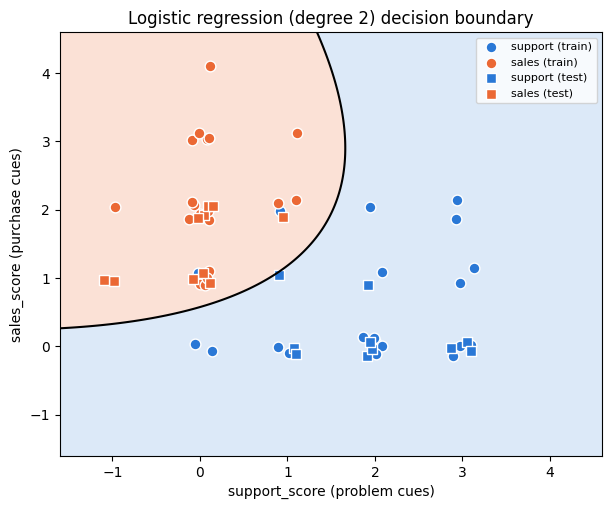

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.5))
xx, yy = np.meshgrid(np.linspace(-1.6, 4.6, 300), np.linspace(-1.6, 4.6, 300))
P = ml.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
ax.contourf(xx, yy, P, levels=[0, .5, 1], colors=["#dce9f8", "#fbe1d6"]); ax.contour(xx, yy, P, levels=[.5], colors="k")
rng = np.random.default_rng(1); j = lambda v: v + rng.uniform(-.15, .15, len(v))
for split, mk in [("train", "o"), ("test", "s")]:
    for lab, col, nm in [(0, "#2a78d6", "support"), (1, "#eb6834", "sales")]:
        d = df[(df.split == split) & (df.label == lab)]
        ax.scatter(j(d.support_score), j(d.sales_score), marker=mk, c=col, edgecolors="w", s=60, label=f"{nm} ({split})")
ax.set_xlabel("support_score (problem cues)"); ax.set_ylabel("sales_score (purchase cues)")
ax.set_title("Logistic regression (degree 2) decision boundary"); ax.legend(fontsize=8)
plt.savefig("boundary.png", dpi=200, bbox_inches="tight"); plt.show()

In [6]:
# Robustness: 200 random group-wise 40/20 splits
rng = np.random.default_rng(0); accs = []
fam = {p: sorted({g for g in df.group_id if g.startswith(p)}) for p in "SL"}
for _ in range(200):
    tg = set(rng.choice(fam["S"], 5, replace=False)) | set(rng.choice(fam["L"], 5, replace=False))
    mt = df.group_id.isin(tg).values
    m = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), LogisticRegression(max_iter=1000)).fit(X[~mt], df.label[~mt])
    accs.append((m.predict(X[mt]) == df.label[mt]).mean())
print(f"200 group splits: mean {np.mean(accs):.3f}, worst {np.min(accs):.2f}, best {np.max(accs):.2f}")

200 group splits: mean 0.964, worst 0.85, best 1.00


## 3 · Decision model: `facebook/bart-large-mnli` (MIT licence)
A natural-language-inference model used as a **zero-shot decision model**: for each message it scores how strongly the message *entails* each routing option. The **routing instructions** are written as the two options. A small wrapper turns the scores into a **validated structured output** `{route, p_support, p_sales}` and maps it to the same flag. Business rule *"existing problems first"*: route to support when `p_support ≥ t`; the threshold `t` is chosen on the **training messages only**.

In [7]:
from transformers import pipeline
zsc = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=-1)
OPTIONS = {
  "customer_service": "has a problem, fault or complaint about a product, order or service they already have",
  "sales": "wants to buy, lease, upgrade or get a price for something new",
}
TEMPLATE = "The customer {}."
def scores(message):
    r = zsc(message, candidate_labels=list(OPTIONS.values()), hypothesis_template=TEMPLATE, multi_label=True)
    s = dict(zip(r["labels"], r["scores"]))
    return s[OPTIONS["customer_service"]], s[OPTIONS["sales"]]
FLAG = {"customer_service": 0, "sales": 1}
def decide(message, t):
    """Structured-output wrapper: returns a validated dict; anything invalid falls back to support."""
    try:
        p_sup, p_sal = scores(message)
        out = {"route": "customer_service" if p_sup >= t else "sales", "p_support": round(p_sup, 3), "p_sales": round(p_sal, 3)}
        assert out["route"] in FLAG and 0 <= out["p_support"] <= 1
    except Exception:
        out = {"route": "customer_service", "p_support": None, "p_sales": None}
    return out
cache = {m: scores(m) for m in list(df.message) + list(stress.message)}   # one model call per message
df["p_support"] = [cache[m][0] for m in df.message]; df["p_sales"] = [cache[m][1] for m in df.message]
stress["p_support"] = [cache[m][0] for m in stress.message]; stress["p_sales"] = [cache[m][1] for m in stress.message]
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
train_acc = [((df.p_support[tr] < t).astype(int) == df.label[tr]).mean() for t in grid]
best = max(train_acc); T = float(min([t for t, a in zip(grid, train_acc) if a == best], key=lambda t: abs(t - 0.5)))
print("threshold chosen on TRAIN:", T, "| train accuracy", round(best, 3))
df["dm_pred"] = (df.p_support < T).astype(int); stress["dm_pred"] = (stress.p_support < T).astype(int)
print(decide("Our CNC lathe stopped and shows alarm 2031, please help.", T))

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

threshold chosen on TRAIN: 0.9 | train accuracy 0.8
{'route': 'customer_service', 'p_support': 0.998, 'p_sales': 0.537}


## 4 · Comparison

                     set  ML classifier  Decision model
0          Test set (20)          1.000           0.800
1       Mixed intent (4)          0.500           1.000
2  New hard messages (8)          0.625           0.625


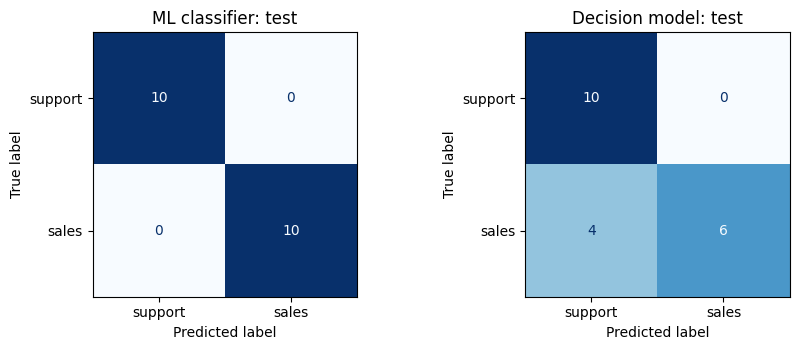

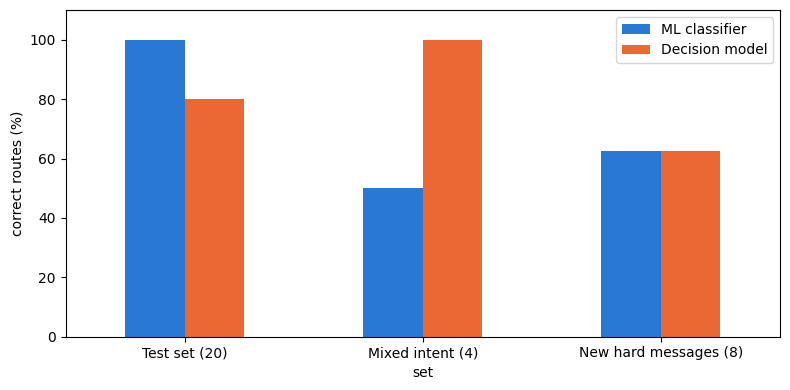

In [8]:
mixed = (df.case_type == "mixed").values
rows = []
for nm, mask in [("Test set (20)", te), ("Mixed intent (4)", mixed)]:
    rows.append([nm, accuracy_score(df.label[mask], df.ml_pred[mask]), accuracy_score(df.label[mask], df.dm_pred[mask])])
rows.append(["New hard messages (8)", accuracy_score(stress.label, stress.ml_pred), accuracy_score(stress.label, stress.dm_pred)])
res = pd.DataFrame(rows, columns=["set", "ML classifier", "Decision model"]); print(res.round(3))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, col, title in [(axs[0], "ml_pred", "ML classifier: test"), (axs[1], "dm_pred", "Decision model: test")]:
    ConfusionMatrixDisplay(confusion_matrix(df.label[te], df[col][te], labels=[0, 1]), display_labels=["support", "sales"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout(); plt.savefig("confusion.png", dpi=200); plt.show()
ax = res.set_index("set").mul(100).plot.bar(rot=0, color=["#2a78d6", "#eb6834"], figsize=(8, 4)); ax.set_ylabel("correct routes (%)"); ax.set_ylim(0, 110)
plt.tight_layout(); plt.savefig("accuracy.png", dpi=200); plt.show()

In [9]:
err = pd.concat([df[te | mixed].assign(set="dataset"), stress.assign(set="stress")])
err = err[(err.ml_pred != err.label) | (err.dm_pred != err.label)]
err[["id", "message", "label", "ml_pred", "dm_pred", "p_support", "p_sales"]]

,id,message,label,ml_pred,dm_pred,p_support,p_sales
7,M08,"Before we talk about buying more robots, the w...",0,1,0,0.916333,0.969960
26,M27,"We like the new spindle package idea, but firs...",0,1,0,0.996612,0.975962
32,M33,What packages do you offer for predictive main...,1,1,0,0.975642,0.970902
42,M43,I'd like to upgrade our maintenance contract t...,1,1,0,0.945191,0.990430
43,M44,Can we move from the basic to the premium serv...,1,1,0,0.937106,0.993475
51,M52,We need your latest chiller brochure with prices.,1,1,0,0.979455,0.997125
0,X1,"Your quote said 4 weeks, but the CNC we bought...",0,1,0,0.999254,0.967490
1,X2,"We're not unhappy with your service, we just w...",1,1,0,0.996060,0.988810
4,X5,We can't decide between your two compressors -...,1,0,0,0.995928,0.975780
6,X7,Please quote the repair cost for our damaged g...,0,1,0,0.997770,0.851562


## 5 · Agent KIO demo: message in, flag out, agent called

In [10]:
def support_agent(msg): print("   -> SUPPORT AGENT:", msg)
def sales_agent(msg):   print("   -> SALES AGENT:", msg)
AGENTS = {0: support_agent, 1: sales_agent}
def kio_route(msg):
    d = decide(msg, T)                       # decision model (primary)
    flag = FLAG[d["route"]]
    if d["p_support"] is None:               # model unavailable -> ML fallback
        flag = int(ml.predict([featurize(msg)])[0])
    return flag, d
for msg in ["The welding robot we bought last month keeps misaligning, and we may want a quote for a second one later.",
            "No problems at all with our compressors - please send prices for two more units.",
            "Our order for spare filters is three weeks late."]:
    flag, d = kio_route(msg); print(msg, "\n   flag =", flag, d); AGENTS[flag](msg)

The welding robot we bought last month keeps misaligning, and we may want a quote for a second one later. 
   flag = 0 {'route': 'customer_service', 'p_support': 0.999, 'p_sales': 0.996}
   -> SUPPORT AGENT: The welding robot we bought last month keeps misaligning, and we may want a quote for a second one later.
No problems at all with our compressors - please send prices for two more units. 
   flag = 1 {'route': 'sales', 'p_support': 0.362, 'p_sales': 0.997}
   -> SALES AGENT: No problems at all with our compressors - please send prices for two more units.
Our order for spare filters is three weeks late. 
   flag = 0 {'route': 'customer_service', 'p_support': 0.999, 'p_sales': 0.815}
   -> SUPPORT AGENT: Our order for spare filters is three weeks late.


In [11]:
summary = {"threshold": T, "results": res.round(3).values.tolist(),
  "ml_train": float(accuracy_score(df.label[tr], df.ml_pred[tr])), "dm_train": float(best),
  "robust": [round(float(np.mean(accs)), 3), round(float(np.min(accs)), 2)],
  "test": df[te][["id", "label", "ml_pred", "dm_pred"]].assign(p=df[te].p_support.round(2)).values.tolist(),
  "mixed": df[mixed][["id", "label", "ml_pred", "dm_pred"]].assign(p=df[mixed].p_support.round(2)).values.tolist(),
  "stress": stress[["id", "label", "ml_pred", "dm_pred"]].assign(p=stress.p_support.round(2)).values.tolist()}
print("SUMMARY_JSON=" + json.dumps(summary))

SUMMARY_JSON={"threshold": 0.9, "results": [["Test set (20)", 1.0, 0.8], ["Mixed intent (4)", 0.5, 1.0], ["New hard messages (8)", 0.625, 0.625]], "ml_train": 0.95, "dm_train": 0.8, "robust": [0.964, 0.85], "test": [["M01", 0, 0, 0, 1.0], ["M02", 0, 0, 0, 1.0], ["M13", 0, 0, 0, 0.96], ["M14", 0, 0, 0, 1.0], ["M17", 0, 0, 0, 1.0], ["M18", 0, 0, 0, 1.0], ["M19", 0, 0, 0, 1.0], ["M20", 0, 0, 0, 1.0], ["M29", 0, 0, 0, 1.0], ["M30", 0, 0, 0, 0.99], ["M33", 1, 1, 0, 0.98], ["M34", 1, 1, 1, 0.77], ["M43", 1, 1, 0, 0.95], ["M44", 1, 1, 0, 0.94], ["M51", 1, 1, 1, 0.78], ["M52", 1, 1, 0, 0.98], ["M53", 1, 1, 1, 0.08], ["M54", 1, 1, 1, 0.07], ["M55", 1, 1, 1, 0.9], ["M56", 1, 1, 1, 0.47]], "mixed": [["M07", 0, 0, 0, 1.0], ["M08", 0, 1, 0, 0.92], ["M27", 0, 1, 0, 1.0], ["M28", 0, 0, 0, 1.0]], "stress": [["X1", 0, 1, 0, 1.0], ["X2", 1, 1, 0, 1.0], ["X3", 1, 1, 1, 0.07], ["X4", 0, 0, 0, 1.0], ["X5", 1, 0, 0, 1.0], ["X6", 0, 0, 0, 1.0], ["X7", 0, 1, 0, 1.0], ["X8", 1, 1, 0, 0.99]]}
